# HC calibration -- engine pipelines only

Reads `results/calibration_*.csv` (written by `eval/calibration.py`, part of `eval/build_results.sh`).
Same checks as `MixedEffectsModeling/1_cv_analysis.ipynb` (CV) and `2_lobo_calibration.ipynb` (LOBO),
with every engine pipeline x scenario overlaid. Outlier methods are not included.

| split | samples |
|---|---|
| `cv` | every HC, 5-fold CV held-out Z |
| `cv_paired` | CV Z of exactly the LOBO HC kept by the OOD filter (batch seen in training) |
| `lobo` | LOBO Z of the same HC (batch never seen) |

`adaptation` exists for `lobo` only: per-batch mean shift from the other half of the batch's HC.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde, pearsonr, spearmanr

parent_dir = str(Path.cwd().parent)
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from viz_style import FS_ANNOT_LG, FS_ANNOT_SM, apply_style
apply_style()

import _FinalModelingMethodImprovement.config as config

R = config.RESULTS_DIR
FIG_DIR = R / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
gene = pd.read_csv(R / 'calibration_gene.csv')
sample = pd.read_csv(R / 'calibration_sample.csv')
exc = pd.read_csv(R / 'calibration_exceedance.csv')
lobo_batch = pd.read_csv(R / 'calibration_lobo_batch.csv')
ppc = pd.read_csv(R / 'calibration_ppc.csv')

METHOD_ORDER = ['p0', 'p2', 'p3']
NAMES = {'p0': 'p0 current', 'p2': 'p2 RUV', 'p3': 'p3 RUV + length/GC'}
COLORS = {'p0': '#000000', 'p2': '#0072B2', 'p3': '#D55E00'}
STYLES = {'zero_shot': '-', 'adaptation': '--'}
SPLITS = ['cv', 'cv_paired', 'lobo']
STATS = [('mean', 'Mean', 0.0), ('std', 'SD', 1.0), ('skew', 'Skewness', 0.0), ('kurt', 'Excess kurtosis', 0.0)]
pd.set_option('display.width', 250)


def groups(df):
    """(method, scenario) pairs present, in display order."""
    have = set(zip(df['method'], df['scenario']))
    order = [(m, s) for m in METHOD_ORDER for s in ('zero_shot', 'adaptation')]
    return [g for g in order if g in have] + sorted(have - set(order))


def label(m, s):
    return f"{NAMES.get(m, m)} / {s.replace('_', '-')}"


def short(m, s):
    return f"{m} {'zs' if s == 'zero_shot' else 'ad'}"


def common_genes(df):
    """Genes every (method, scenario) of this split reports, so distributions sit on one gene set."""
    sets = [set(g['gene']) for _, g in df.groupby(['method', 'scenario'])]
    return df[df['gene'].isin(set.intersection(*sets))] if sets else df


print(gene.groupby(['split', 'kind', 'method', 'scenario']).size().unstack(['method', 'scenario']))

method                 p0        p2         p0         p2
scenario        zero_shot zero_shot adaptation adaptation
split     kind                                           
cv        raw     19621.0   19539.0        NaN        NaN
          shash   19621.0   19539.0        NaN        NaN
cv_paired raw     19591.0   19501.0        NaN        NaN
          shash   19591.0   19501.0        NaN        NaN
lobo      raw     19591.0   19501.0    19591.0    19501.0
          shash   19591.0   19501.0    19591.0    19501.0


## A. Per-gene Z moments (KDE)

One figure per Z kind; rows = split, columns = moment. Dashed = ideal N(0, 1); lines = pipeline x scenario. Adaptation centres each batch on its own HC, so its per-gene mean is ~0 by construction; that spike is cut at the zero-shot peak height.

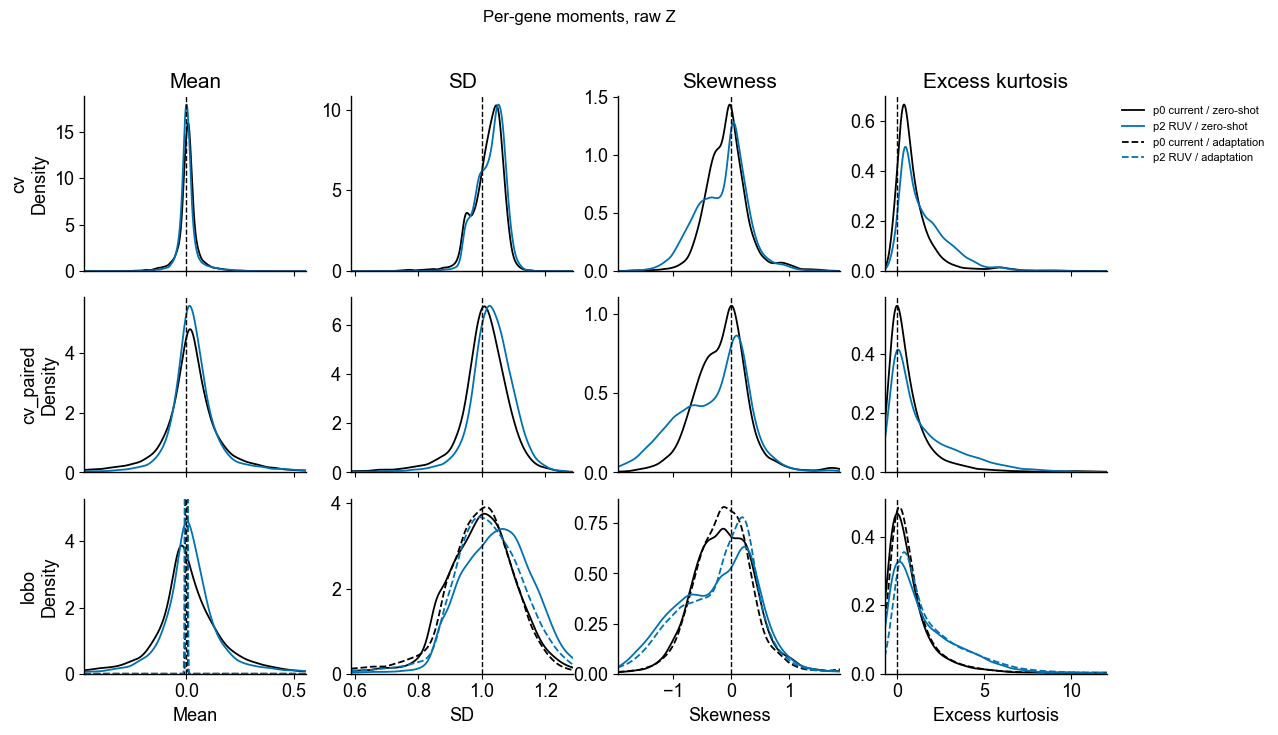

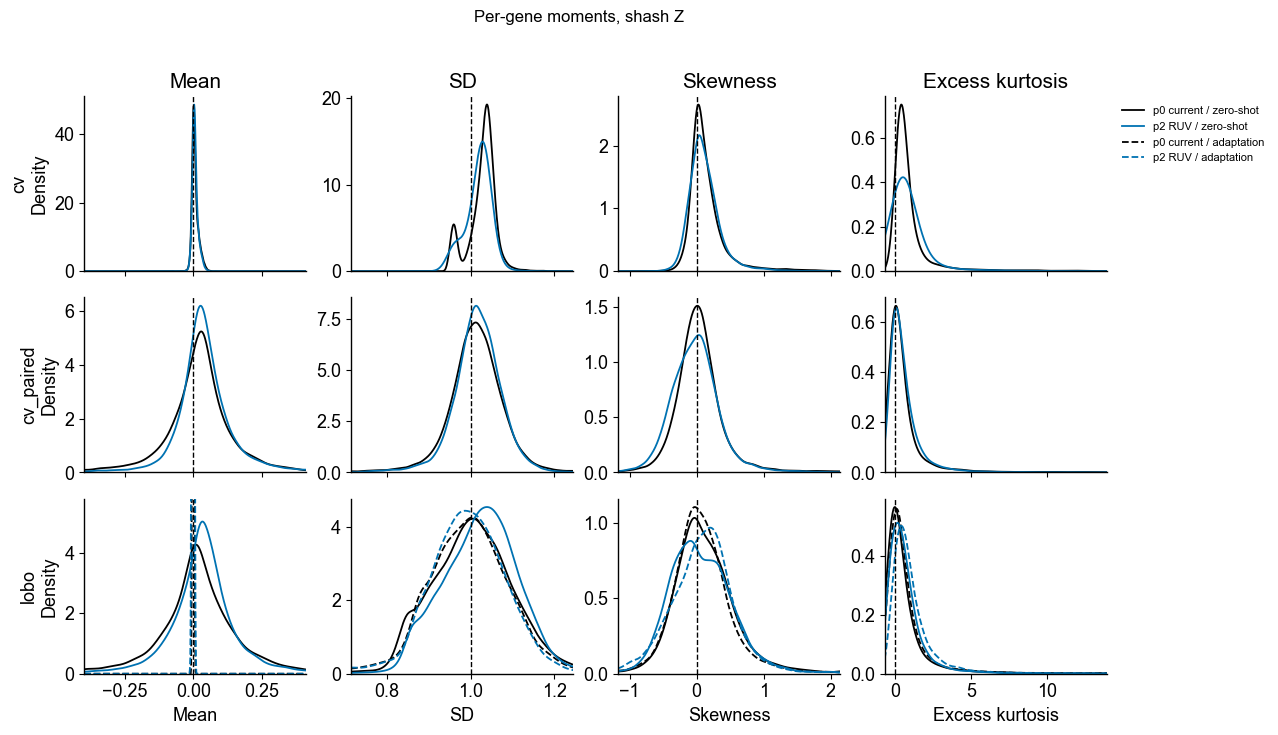

mean     std    skew    kurt  exceed_196
split     kind  method scenario                                              
cv        raw   p0     zero_shot   0.0069  1.0268 -0.0675  0.6260      0.0541
                p2     zero_shot   0.0015  1.0340 -0.0583  1.1118      0.0557
          shash p0     zero_shot   0.0040  1.0341  0.0801  0.5347      0.0541
                p2     zero_shot   0.0050  1.0256  0.0842  0.5441      0.0507
cv_paired raw   p0     zero_shot   0.0196  1.0112 -0.1242  0.2890      0.0529
                p2     zero_shot   0.0235  1.0318 -0.1786  0.7432      0.0558
          shash p0     zero_shot   0.0246  1.0139  0.0155  0.2044      0.0529
                p2     zero_shot   0.0330  1.0176 -0.0241  0.3219      0.0508
lobo      raw   p0     adaptation -0.0003  0.9990 -0.1191  0.4496      0.0476
                       zero_shot  -0.0049  1.0012 -0.1088  0.3625      0.0476
                p2     adaptation -0.0014  1.0183 -0.0784  1.1208      0.0558
                       zero_shot   0.0112  1.0502 -0.1535  0.9514      0.0609
          shash p0     adaptation -0.0003  0.9953  0.0523  0.3267      0.0476
                       zero_shot   0.0146  1.0032  0.0853  0.2082      0.0476
                p2     adaptation -0.0013  0.9931  0.1044  0.7160      0.0508
                       zero_shot   0.0347  1.0262  0.0325  0.4322      0.0558

In [2]:
for kind in ['raw', 'shash']:
    fig, axes = plt.subplots(len(SPLITS), len(STATS), figsize=(3.3 * len(STATS), 2.5 * len(SPLITS)),
                             sharex='col', squeeze=False, gridspec_kw=dict(hspace=0.15))
    for i, split in enumerate(SPLITS):
        d = common_genes(gene[(gene['split'] == split) & (gene['kind'] == kind)])
        for j, (stat, lab, target) in enumerate(STATS):
            ax = axes[i, j]
            all_v = gene.loc[gene['kind'] == kind, stat].dropna()
            lo, hi = np.nanpercentile(all_v, [0.5, 99.5])
            grid = np.linspace(lo, hi, 512)
            peaks = []
            for m, s in groups(d):
                v = d.loc[(d['method'] == m) & (d['scenario'] == s), stat].dropna().values
                if len(v) > 1:
                    y = gaussian_kde(v)(grid)
                    peaks.append((s, y.max()))
                    ax.plot(grid, y, color=COLORS.get(m, '#888888'), ls=STYLES.get(s, ':'),
                            lw=1.3, label=label(m, s))
            ax.axvline(target, color='black', ls='--', lw=1)
            ax.set_xlim(lo, hi)
            zs = [p for sc, p in peaks if sc == 'zero_shot']
            ax.set_ylim(0, 1.15 * max(zs) if stat == 'mean' and zs and max(p for _, p in peaks) > 3 * max(zs) else None)
            if i == 0:
                ax.set_title(lab)
            if j == 0:
                ax.set_ylabel(f'{split}\nDensity')
            if i == len(SPLITS) - 1:
                ax.set_xlabel(lab)
    hl = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
    axes[0, -1].legend(hl.values(), hl.keys(), frameon=False, fontsize=FS_ANNOT_SM, loc='upper left', bbox_to_anchor=(1.02, 1))
    fig.suptitle(f'Per-gene moments, {kind} Z', y=0.995)
    fig.savefig(FIG_DIR / f'calibration_moments_{kind}.png', dpi=300, bbox_inches='tight')
    plt.show()

med = gene.groupby(['split', 'kind', 'method', 'scenario'])[[s for s, _, _ in STATS] + ['exceed_196']].median()
display(med.round(4))

## B. Exceedance

Left: observed P(p < alpha) vs nominal alpha, SHASH Z, one line per held-out batch. Right: per-gene |Z| > 1.96 rate (violin, target 5%). Violin labels: `zs` = zero-shot, `ad` = adaptation (hatched).

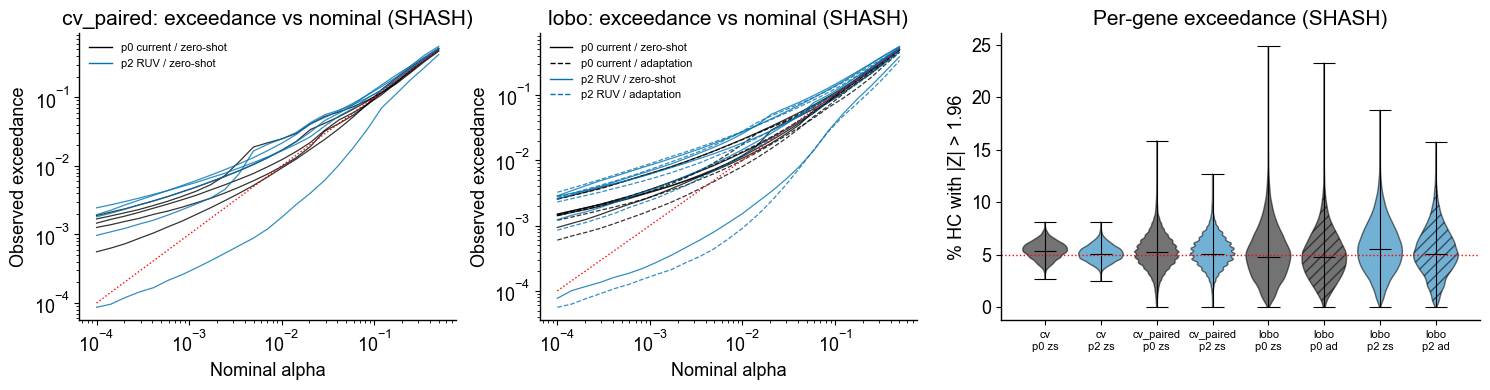

In [3]:
def violins(ax, data, labels, colors, hatches=None):
    pos = np.arange(len(data))
    parts = ax.violinplot([d if len(d) else [np.nan] for d in data], positions=pos, showmedians=True, widths=0.8)
    for k, b in enumerate(parts['bodies']):
        b.set_facecolor(colors[k]); b.set_edgecolor('black'); b.set_alpha(0.55)
        if hatches:
            b.set_hatch(hatches[k])
    for key in ('cmedians', 'cbars', 'cmins', 'cmaxes'):
        parts[key].set_color('black'); parts[key].set_linewidth(0.8)
    ax.set_xticks(pos); ax.set_xticklabels(labels, fontsize=FS_ANNOT_SM)


HATCH = {'zero_shot': '', 'adaptation': '///'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1.1, 1.1, 1.4]))
for ax, split in zip(axes[:2], ['cv_paired', 'lobo']):
    e = exc[exc['split'] == split]
    for m, s in groups(e):
        for b, sub in e[(e['method'] == m) & (e['scenario'] == s)].groupby('batch'):
            ax.plot(sub['alpha'], sub['exceed'], color=COLORS.get(m, '#888888'), ls=STYLES.get(s, ':'), lw=0.9, alpha=0.8)
        ax.plot([], [], color=COLORS.get(m, '#888888'), ls=STYLES.get(s, ':'), label=label(m, s))
    a = np.array(sorted(e['alpha'].unique()))
    ax.plot(a, a, color='red', ls=':', lw=1)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Nominal alpha'); ax.set_ylabel('Observed exceedance')
    ax.set_title(f'{split}: exceedance vs nominal (SHASH)')
    ax.legend(frameon=False, fontsize=FS_ANNOT_SM)
d = gene[gene['kind'] == 'shash']
keys = [(sp, m, s) for sp in SPLITS for m, s in groups(d[d['split'] == sp])]
violins(axes[2], [100 * common_genes(d[d['split'] == sp]).query('method == @m and scenario == @s')['exceed_196'].values
                  for sp, m, s in keys],
        [f'{sp}\n{short(m, s)}' for sp, m, s in keys], [COLORS.get(m, '#888888') for _, m, _ in keys],
        [HATCH.get(s, '') for _, _, s in keys])
axes[2].axhline(5, color='red', ls=':', lw=1)
axes[2].set_ylabel('% HC with |Z| > 1.96')
axes[2].set_title('Per-gene exceedance (SHASH)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'calibration_exceedance.png', dpi=300, bbox_inches='tight')
plt.show()

## C. BH outliers

Top: per gene, BH across the split's HC (outlier samples per gene, SHASH Z). Bottom: per sample, BH across genes at q = 0.05 (false calls), violin per held-out batch.

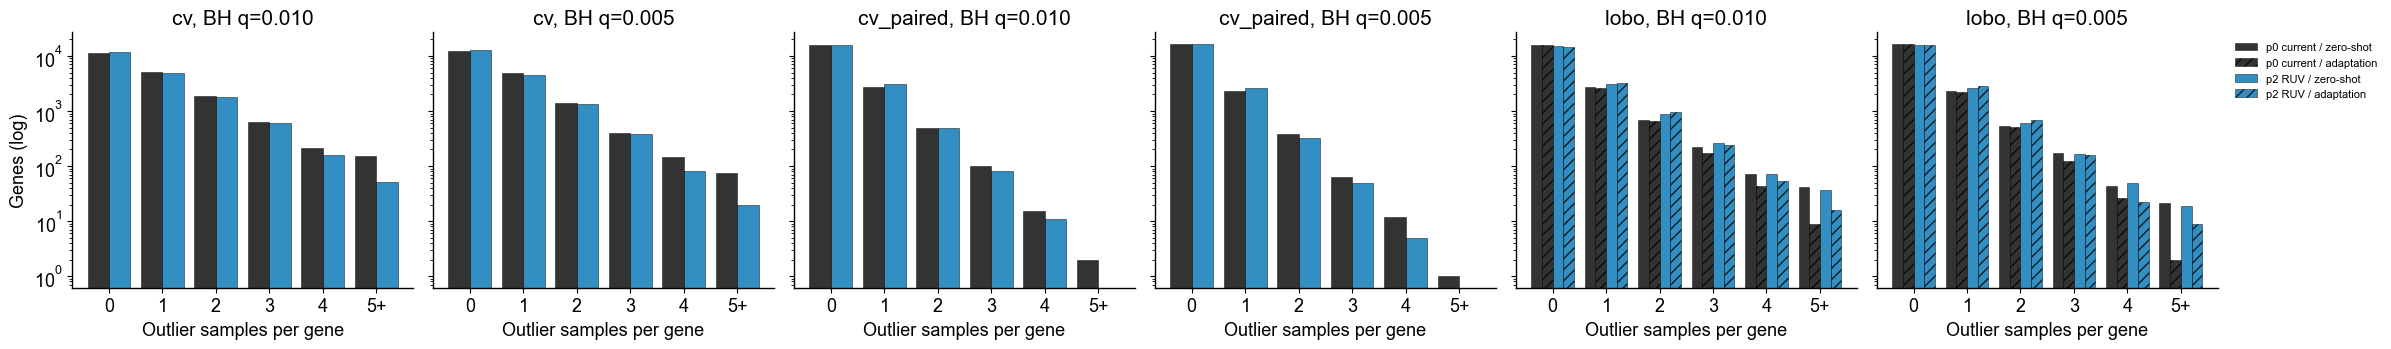

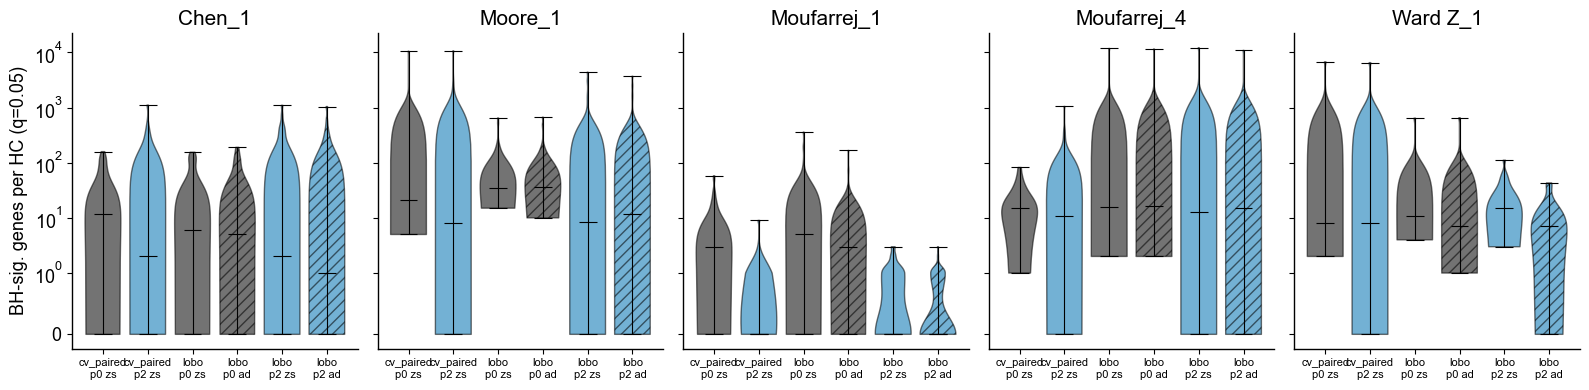

In [4]:
CAT = ['0', '1', '2', '3', '4', '5+']
fig, axes = plt.subplots(1, 2 * len(SPLITS), figsize=(4 * 2 * len(SPLITS), 3.6), sharey=True)
for k, (split, q) in enumerate([(sp, q) for sp in SPLITS for q in ('nout_q010', 'nout_q005')]):
    ax = axes[k]
    d = common_genes(gene[(gene['split'] == split) & (gene['kind'] == 'shash')])
    gs = groups(d)
    w = 0.8 / max(len(gs), 1)
    for i, (m, s) in enumerate(gs):
        v = d.loc[(d['method'] == m) & (d['scenario'] == s), q].clip(upper=5)
        cnt = v.value_counts().reindex(range(6)).fillna(0).values
        ax.bar(np.arange(6) + (i - (len(gs) - 1) / 2) * w, cnt, w, color=COLORS.get(m, '#888888'),
               hatch=HATCH.get(s, ''), alpha=0.8, edgecolor='black', lw=0.4, label=label(m, s))
    ax.set_yscale('log'); ax.set_xticks(range(6)); ax.set_xticklabels(CAT)
    ax.set_title(f'{split}, BH q={int(q[-3:]) / 1000:.3f}')
    ax.set_xlabel('Outlier samples per gene')
axes[0].set_ylabel('Genes (log)')
axes[-1].legend(frameon=False, fontsize=FS_ANNOT_SM, loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout()
fig.savefig(FIG_DIR / 'calibration_gene_outliers.png', dpi=300, bbox_inches='tight')
plt.show()

batches = sorted(sample['batch'].unique())
fig, axes = plt.subplots(1, len(batches), figsize=(3.2 * len(batches), 4), sharey=True, squeeze=False)
for ax, b in zip(axes[0], batches):
    sb = sample[sample['batch'] == b]
    keys = [(sp, m, s) for sp in ['cv_paired', 'lobo'] for m, s in groups(sb[sb['split'] == sp])]
    data = [sb.query('split == @sp and method == @m and scenario == @s')['n_sig'].values for sp, m, s in keys]
    violins(ax, data, [f'{sp}\n{short(m, s)}' for sp, m, s in keys], [COLORS.get(m, '#888888') for _, m, _ in keys],
            [HATCH.get(s, '') for _, _, s in keys])
    ax.set_yscale('symlog', linthresh=1)
    ax.set_title(b.replace(' et al._Batch_', '_'))
axes[0, 0].set_ylabel('BH-sig. genes per HC (q=0.05)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'calibration_sample_nsig.png', dpi=300, bbox_inches='tight')
plt.show()

### Summary per held-out batch (SHASH)

In [5]:
display(lobo_batch.set_index(['batch', 'split', 'method', 'scenario']).drop(columns='n_hc').unstack(['split', 'method', 'scenario']).round(4).T)

batch                                           Chen et al._Batch_1  Moore et al._Batch_1  Moufarrej et al._Batch_1  Moufarrej et al._Batch_4  Ward Z et al._Batch_1
                   split     method scenario                                                                                                                        
median_gene_mean   cv_paired p0     zero_shot                0.0933               -0.0940                    0.0406                    0.0637                 0.0192
                   lobo      p0     zero_shot               -0.0482               -0.0556                    0.0306                    0.0729                 0.0373
                                    adaptation              -0.0024                0.0000                    0.0000                    0.0000                 0.0000
                   cv_paired p2     zero_shot                0.1395               -0.1579                    0.0915                   -0.0043                 0.1699
                   lobo      p2     zero_shot                0.0798               -0.1444                    0.1330                   -0.0020                 0.1061
                                    adaptation              -0.0014                0.0000                    0.0000                   -0.0042                -0.0036
median_gene_sd     cv_paired p0     zero_shot                0.9496                1.0016                    0.9728                    0.9667                 0.9449
                   lobo      p0     zero_shot                0.9145                0.9823                    0.8737                    0.9544                 0.8494
                                    adaptation               0.9550                1.0098                    0.9067                    0.9937                 0.8854
                   cv_paired p2     zero_shot                0.9723                1.0449                    0.7470                    1.0539                 0.9377
                   lobo      p2     zero_shot                0.9531                1.0537                    0.7007                    1.0675                 0.8690
                                    adaptation               0.9804                1.0824                    0.7229                    1.1021                 0.9152
exceed_196         cv_paired p0     zero_shot                0.0528                0.0591                    0.0425                    0.0476                 0.0665
                   lobo      p0     zero_shot                0.0462                0.0619                    0.0446                    0.0540                 0.0437
                                    adaptation               0.0477                0.0593                    0.0392                    0.0568                 0.0381
                   cv_paired p2     zero_shot                0.0605                0.0721                    0.0137                    0.0673                 0.0713
                   lobo      p2     zero_shot                0.0562                0.0803                    0.0108                    0.0878                 0.0595
                                    adaptation               0.0572                0.0747                    0.0106                    0.0825                 0.0464
exceed_329         cv_paired p0     zero_shot                0.0035                0.0045                    0.0017                    0.0027                 0.0039
                   lobo      p0     zero_shot                0.0036                0.0063                    0.0027                    0.0033                 0.0032
                                    adaptation               0.0036                0.0062                    0.0017                    0.0033                 0.0027
                   cv_paired p2     zero_shot                0.0054                0.0056                    0.0003                    0.0045                 0.0025
                   lobo      p2     zero

## D. CV posterior-predictive check

Observed vs replicated per-gene mean, SD and zero fraction on the CV held-out HC (200 replicates per gene).

,,,pearson_r,r2,spearman_rho,rmse,mae,n
moment,method,scenario,,,,,,
Mean,p0 current,zero_shot,0.9944,0.9887,0.9951,0.1133,0.0477,19917
SD,p0 current,zero_shot,0.9691,0.9391,0.9750,0.2569,0.1543,19917
Zero fraction,p0 current,zero_shot,0.9992,0.9985,0.9984,0.0202,0.0151,19917
Mean,p2 RUV,zero_shot,0.9739,0.9486,0.9800,0.2349,0.0547,19869
SD,p2 RUV,zero_shot,0.9302,0.8654,0.9528,0.3483,0.1342,19869
Zero fraction,p2 RUV,zero_shot,0.9987,0.9974,0.9972,0.0288,0.0214,19869


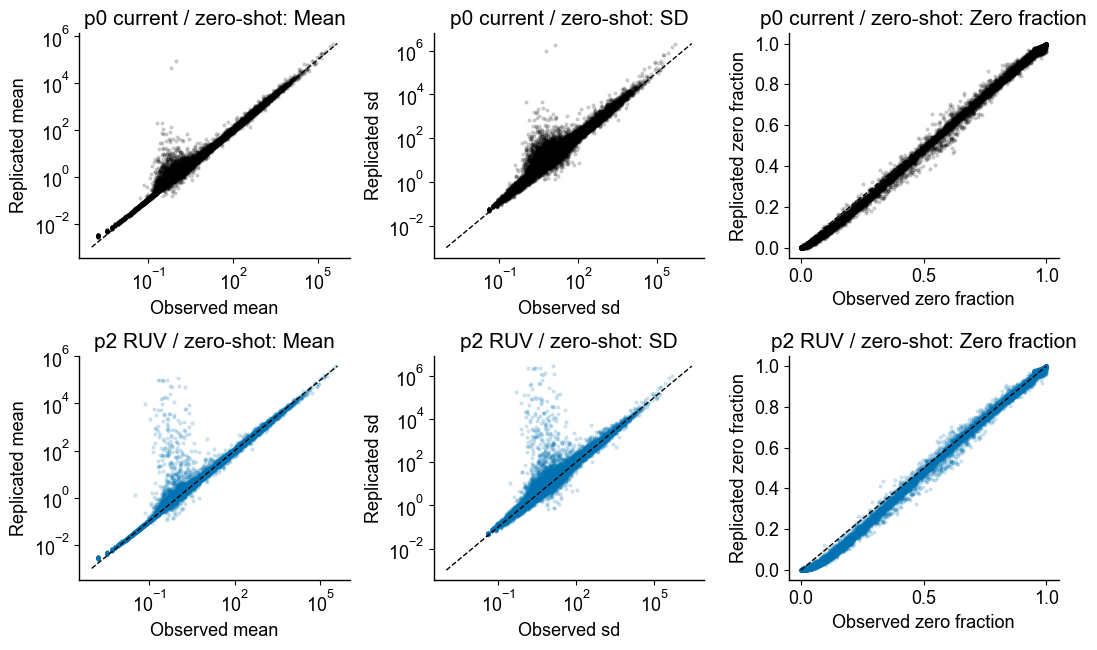

In [6]:
def calib_stats(o, p, logscale):
    o, p = np.asarray(o, float), np.asarray(p, float)
    m = np.isfinite(o) & np.isfinite(p)
    o, p = o[m], p[m]
    if logscale:
        o, p = np.log10(o + 1), np.log10(p + 1)
    return dict(pearson_r=pearsonr(o, p)[0], r2=pearsonr(o, p)[0] ** 2, spearman_rho=spearmanr(o, p)[0],
                rmse=float(np.sqrt(np.mean((p - o) ** 2))), mae=float(np.mean(np.abs(p - o))), n=len(o))


PANELS = [('mean', 'Mean', True), ('sd', 'SD', True), ('zero', 'Zero fraction', False)]
rows = []
for (m, s), d in ppc.groupby(['method', 'scenario']):
    for key, lab, logsc in PANELS:
        rows.append(dict(method=NAMES.get(m, m), scenario=s, moment=lab, **calib_stats(d[f'obs_{key}'], d[f'pred_{key}'], logsc)))
display(pd.DataFrame(rows).set_index(['moment', 'method', 'scenario']).round(4))

gs = groups(ppc)
fig, axes = plt.subplots(len(gs), len(PANELS), figsize=(3.6 * len(PANELS), 3.3 * len(gs)), squeeze=False)
for i, (m, s) in enumerate(gs):
    d = ppc[(ppc['method'] == m) & (ppc['scenario'] == s)]
    for j, (key, lab, logsc) in enumerate(PANELS):
        ax = axes[i, j]
        ax.scatter(d[f'obs_{key}'], d[f'pred_{key}'], s=4, alpha=0.15, color=COLORS.get(m, '#888888'))
        lo = max(min(d[f'obs_{key}'].min(), d[f'pred_{key}'].min()), 1e-3) if logsc else 0
        hi = max(d[f'obs_{key}'].max(), d[f'pred_{key}'].max()) if logsc else 1
        ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
        if logsc:
            ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'{label(m, s)}: {lab}')
        ax.set_xlabel(f'Observed {lab.lower()}'); ax.set_ylabel(f'Replicated {lab.lower()}')
fig.tight_layout()
fig.savefig(FIG_DIR / 'calibration_ppc.png', dpi=300, bbox_inches='tight')
plt.show()